# Modular EDA
## Heart Disease Classification

Exploración de datos (EDA) utilizando la nueva estructura modular de cookie cutter.


### Datos a utilizar

Para este entrenamiento vamos a utilizar el dataset de heart disease de Kaggl. Se describe a continuación cada columna:

* Age: Edad de la persona.
* Sex: Sexo de la persona.
* ChestPainType: Tipo de dolor de pecho. TA=Typical Angina, ATA=Atypical Angina, NAP=Non-Anginal Pain, ASY=Asymptomatic.
* RestingBP: Presión sanguínea en reposo.
* Cholesterol: Nivel de colesterol.
* FastingBS: Presión sanguínea en ayunas.
* RestingECG: Resultados de electrocardiograma en reposo.
* MaxHR: Máximo número de pulsaciones del corazón.
* ExcerciseAngina: Angina en ejercisio. 
* Oldpeak: Depresión del segmento ST.
* ST_Slope: Pendiente del segmento ST durante el esfuerzo máximo.
* HeartDisease: Variable objetivo, en este caso 1 nos indica que hay un problema cardiaco y 0 que no hay.


In [ ]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow


from heart_ccds.config import (
    RAW_DATA_PATH,
    TARGET,
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES,
    DEFAULT_RANDOM_STATE,
    DEFAULT_EXPERIMENT_NAME,
    MLFLOW_TRACKING_URI,
)
from heart_ccds.dataset import load_data, clean_data
from heart_ccds.features import build_preprocessor, split_data
from heart_ccds.plots import (
    plot_numeric_histograms,
    plot_numeric_boxplots,
    plot_categorical_counts,
)

In [2]:
df = load_data(RAW_DATA_PATH)
df.head()


2026-10-11 15:46:46,746 | INFO     | heart_modular - Loading raw data from: /home/miguel/Maestria/Trimestre4/mlops/heart-modular/data/raw/heart.csv
2026-10-11 15:46:46,749 | INFO     | heart_modular - Successfully loaded dataset with shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## Exploratory Data Analysis (EDA)

In [7]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [8]:
df.describe(include=['object'])

/tmp/ipykernel_104496/3011300674.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=['object'])


,Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope
count,918,918,918,918,918
unique,2,4,3,2,3
top,M,ASY,Normal,N,Flat
freq,725,496,552,547,460


In [9]:
df.isna().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

<Figure size 1500x1000 with 0 Axes>

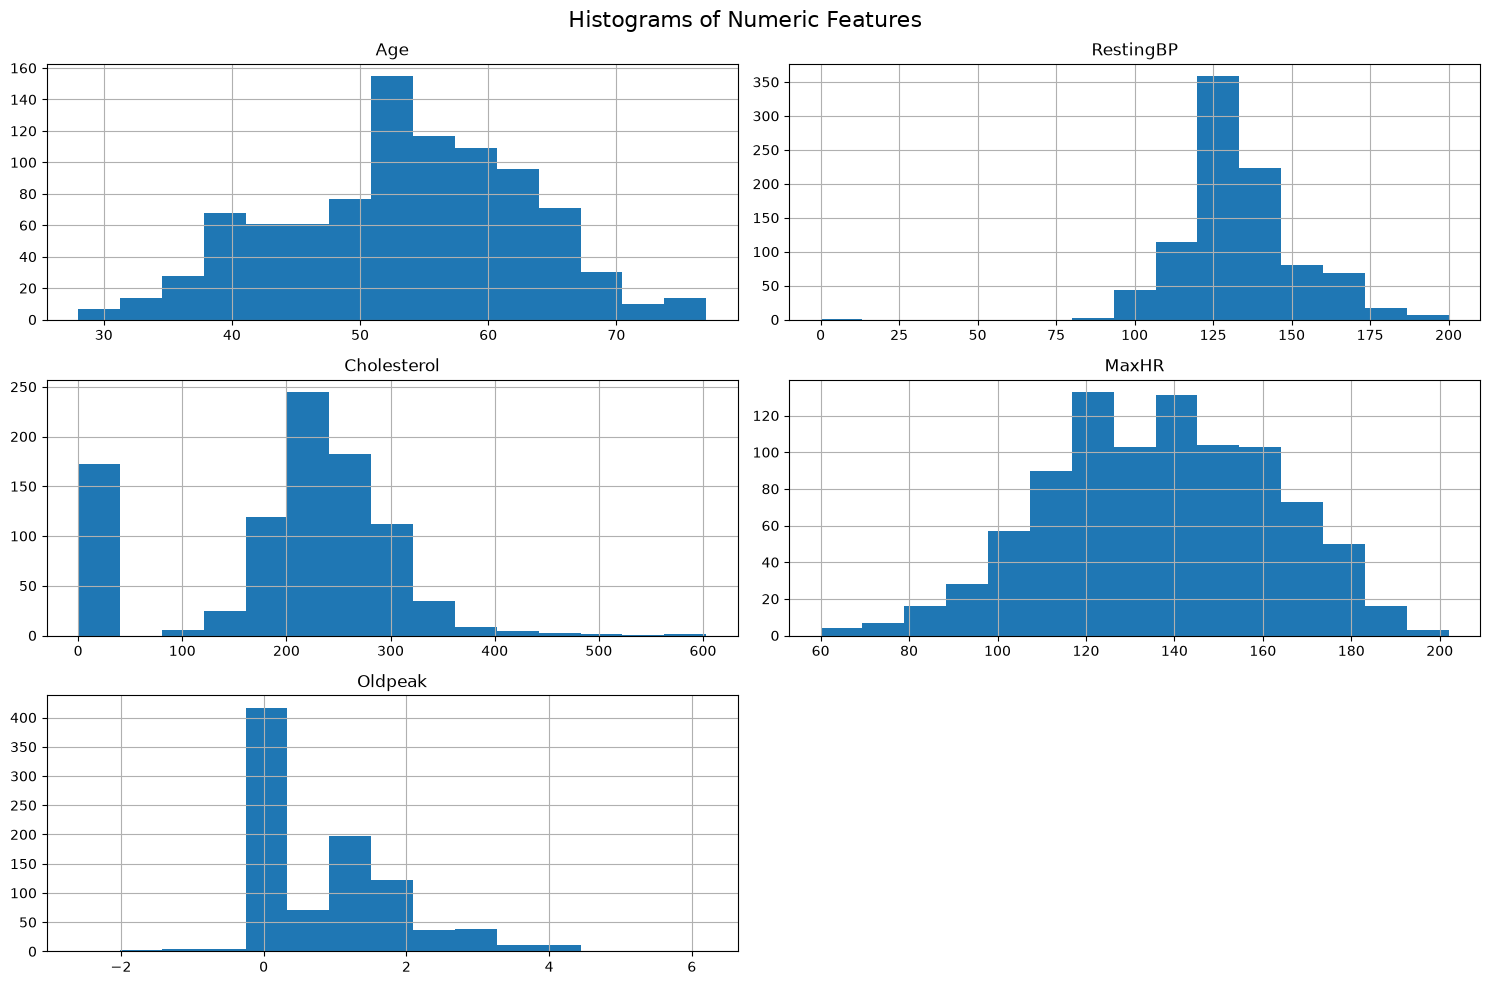

In [3]:
plot_numeric_histograms(df, NUMERIC_FEATURES)
plt.show()


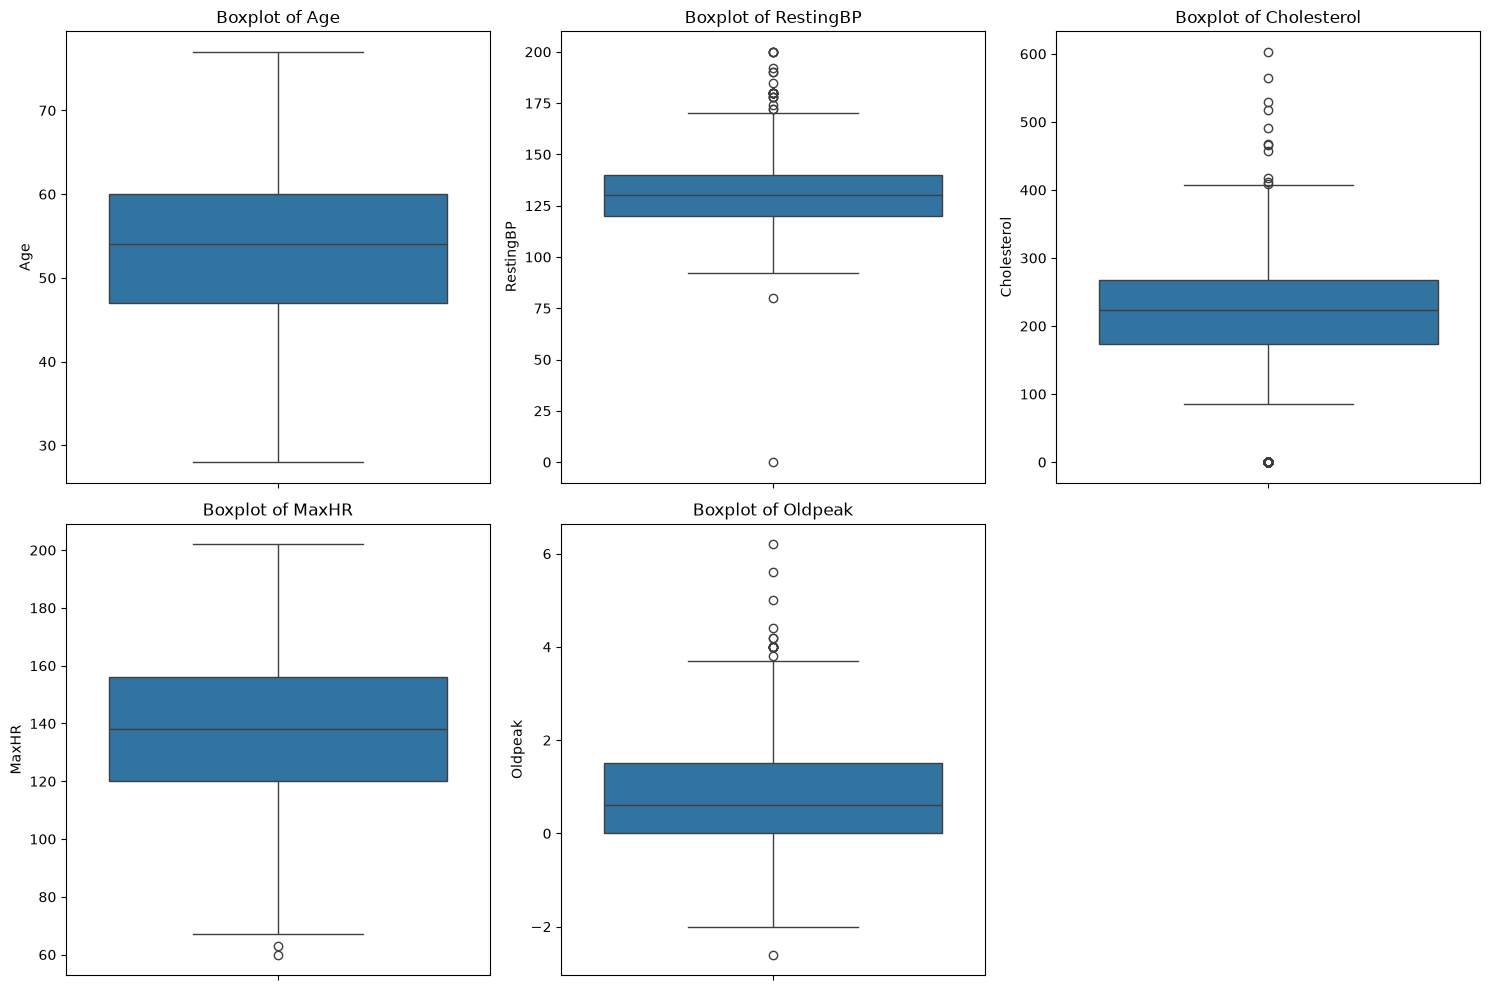

In [4]:
plot_numeric_boxplots(df, NUMERIC_FEATURES)
plt.show()


2026-10-11 15:47:17,408 | INFO     | matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-11 15:47:17,410 | INFO     | matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-11 15:47:17,448 | INFO     | matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-11 15:47:17,450 | INFO     | matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


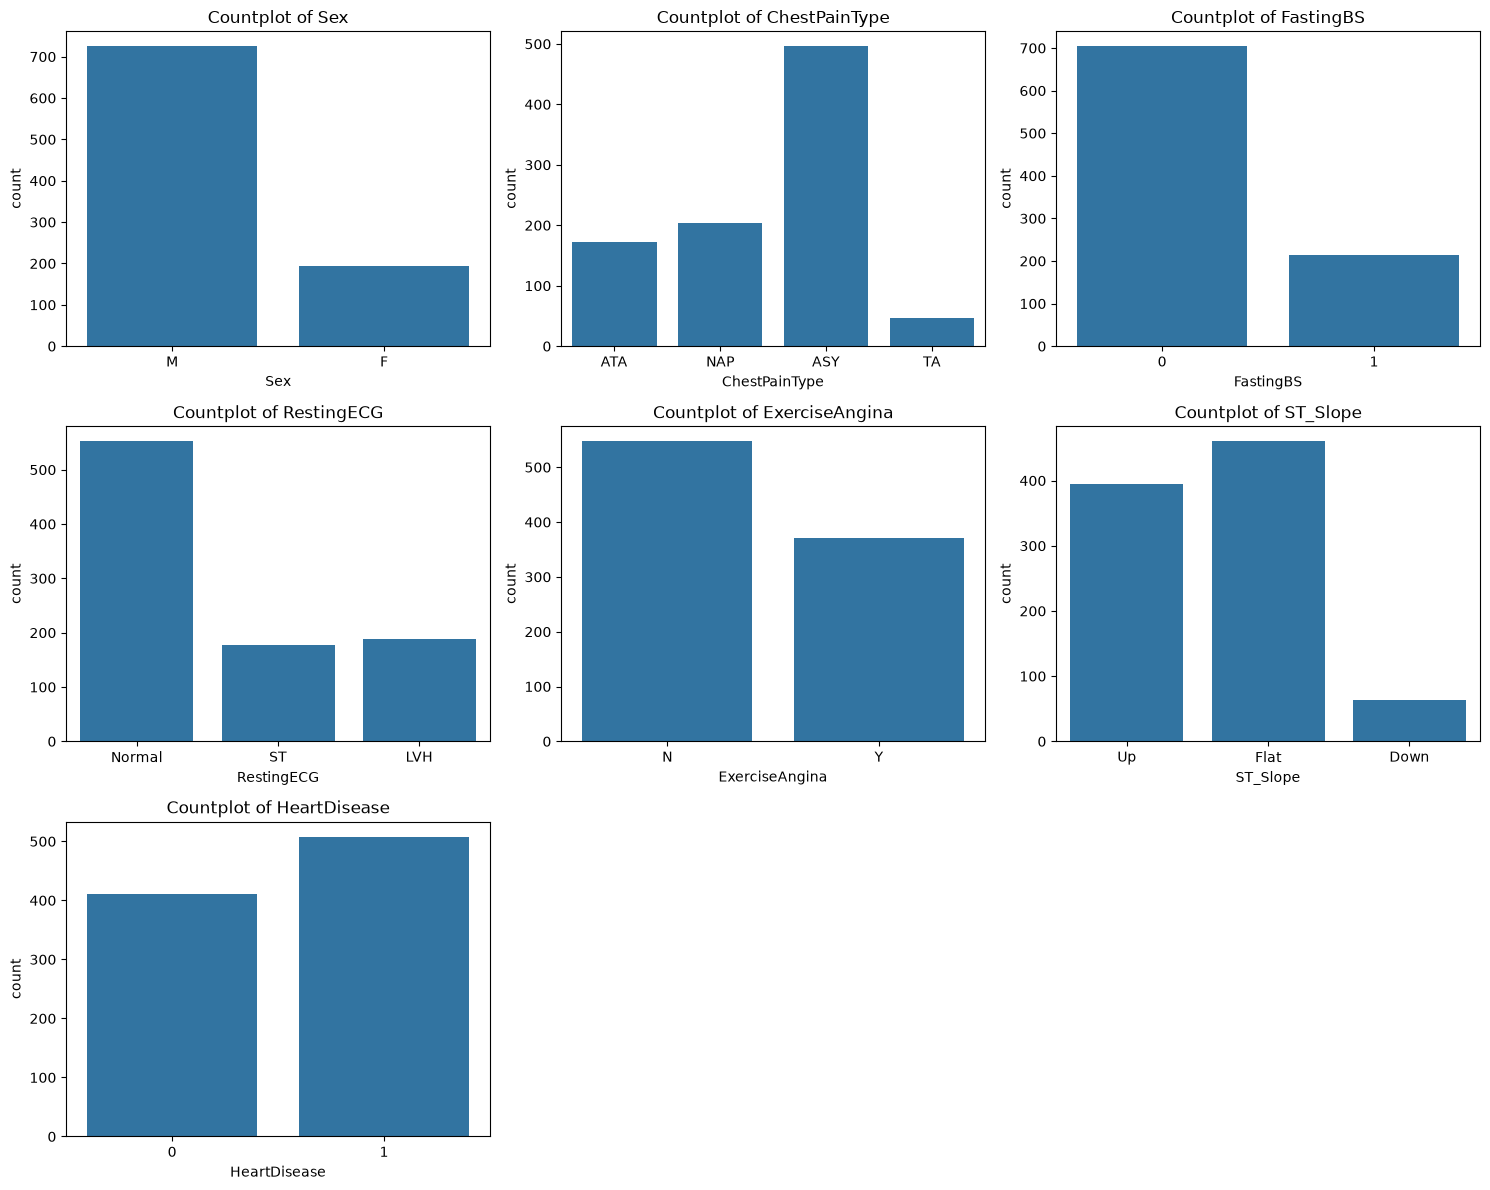

In [5]:
plot_categorical_counts(df, CATEGORICAL_FEATURES, TARGET)
plt.show()


In [ ]:
# 2. Modular Data Cleaning & Validation
df_clean = clean_data(df)
df_clean.info()
